# Avance 1 · Capítulo 7 — Datos MEXC, particiones TR–VA–TE y modelos de referencia
**Práctica de Deep Learning para Finanzas** · Activos: BTCUSDT, ETHUSDT, SOLUSDT, ADAUSDT (velas diarias, MEXC Spot)

**Objetivo.** Preparar datos confiables y fijar referencias (pronóstico cero y regresión lineal) para valorar después el aporte del modelo profundo.

**Qué pronosticamos.** Al cierre del día *t*: `y_t = P_{t+1} / P_t − 1`, con los **20 rendimientos más recientes hasta *t*** como entrada.

**Reglas que respeta este notebook**
- Separación temporal **70 / 15 / 15** según la **fecha del objetivo** (sin aleatoriedad) y con fechas de corte **comunes** a los 4 activos.
- Escalador ajustado **solo con TR**; VA y TE solo se transforman.
- MAE y RMSE **solo en TR y VA**. **TE no se evalúa aquí.**
- No se rellenan huecos ni se inventa volumen. Errores con excepciones específicas (sin `except: pass`) y bitácora.

**Ejecución:** *Run all*, de arriba hacia abajo. Requiere Internet (API pública de MEXC). Este avance no entrena redes, por lo que corre en CPU; la evidencia de T4 empieza en el Avance 2.

> Finalidad académica. Nada de esto es una recomendación de inversión.

## 0. Configuración, versiones y semilla

In [1]:
import json, pickle, platform, sys, time, warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests
import sklearn
import scipy
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# ------------------------- Parámetros editables -------------------------
SEED = 42
np.random.seed(SEED)

SIMBOLOS = ["BTCUSDT", "ETHUSDT", "SOLUSDT", "ADAUSDT"]
INTERVALO = "1d"
INICIO_DESCARGA = "2017-01-01"      # si el par no existía, MEXC devuelve desde su primera vela
LAGS = 20                           # ventana de entrada: 20 rendimientos
MIN_OBS = 1500                      # observaciones válidas mínimas por serie (antes de ventanas)
FRAC_TR, FRAC_VA = 0.70, 0.15       # TE = el 15 % restante
PERIODO_COMUN = True                # True: los 4 activos usan el mismo periodo (recomendado)
USAR_COPIA_LOCAL = False            # True: usa data/raw/*.csv ya descargados (debe tener metadatos)
MEXC_URL = "https://api.mexc.com/api/v3/klines"
DIA_MS = 86_400_000
# -------------------------------------------------------------------------

try:                                 # en Colab se guarda en Drive (fuera del almacenamiento temporal)
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/bot-trading")
except ImportError:                  # en local: raíz del repo aunque se ejecute desde notebooks/
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, MODELS, OUT, FIG = (ROOT / "data" / "raw", ROOT / "data" / "processed",
                               ROOT / "models", ROOT / "outputs", ROOT / "figures")
for d in (RAW, PROC, MODELS, OUT, FIG):
    d.mkdir(parents=True, exist_ok=True)

FECHA_EJECUCION = datetime.now(timezone.utc)
VERSIONES = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
             "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "matplotlib": matplotlib.__version__,
             "requests": requests.__version__, "semilla": SEED, "dispositivo": "CPU (Avance 1: sin redes profundas)",
             "fecha_ejecucion_utc": FECHA_EJECUCION.isoformat(timespec="seconds")}
(OUT / "versiones.json").write_text(json.dumps(VERSIONES, indent=2, ensure_ascii=False), encoding="utf-8")
print("Carpeta raíz:", ROOT)
print(VERSIONES)

Carpeta raíz: C:\Users\Diego Horner\Documents\traidingbot\bottrading
{'python': '3.12.5', 'pandas': '3.1.1', 'numpy': '2.5.5', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'requests': '2.34.2', 'semilla': 42, 'dispositivo': 'CPU (Avance 1: sin redes profundas)', 'fecha_ejecucion_utc': '2026-11-18T05:03:05+00:00'}


## 1. Excepciones propias y bitácora
Cada fallo se captura con una excepción **específica** y deja un mensaje que explica cómo resolverlo. La bitácora sigue el formato
`fecha | etapa | error | causa | acción correctiva | verificación` y se guarda en `outputs/bitacora.csv`.

In [2]:
class DescargaError(RuntimeError):
    pass
class DatosVaciosError(ValueError):
    pass
class FechaDuplicadaError(ValueError):
    pass
class ValorInvalidoError(ValueError):
    pass
class DimensionError(ValueError):
    pass
class DatosInsuficientesError(ValueError):
    pass
class FugaInformacionError(RuntimeError):
    pass
class PrediccionNoFinitaError(ValueError):
    pass

BITACORA = []
def registrar(etapa, error, causa, accion, verificacion):
    BITACORA.append(dict(fecha=datetime.now(timezone.utc).isoformat(timespec="seconds"), etapa=etapa,
                         error=error, causa=causa, accion_correctiva=accion, verificacion=verificacion))

def control(condicion, mensaje, excepcion=ValueError):
    # Detiene el flujo con un mensaje claro si la condición no se cumple.
    if not condicion:
        raise excepcion(mensaje)

## 2. Descarga desde MEXC (API pública, sin claves)
`GET /api/v3/klines` devuelve **máximo 500 velas por llamada**, así que se pagina por ventanas con `startTime` + `endTime` (sin `endTime`, MEXC ignora `startTime`). Reintentos limitados con espera creciente (1, 2, 4, 8 s).
Si falla tras los reintentos se **detiene el flujo** e informa símbolo y causa. Los datos originales se guardan **antes de limpiar** en `data/raw/` junto con sus metadatos.

> Verifica los parámetros en la documentación vigente de MEXC antes de entregar. Cada fila trae: tiempo de apertura (ms), open, high, low, close, volumen (en moneda base), tiempo de cierre y volumen en moneda cotizada.

In [3]:
COLS_KL = ["open_time", "open", "high", "low", "close", "volume", "close_time", "quote_volume"]

def descargar_klines(simbolo, inicio=INICIO_DESCARGA, max_reintentos=4):
    cursor = int(pd.Timestamp(inicio, tz="UTC").timestamp() * 1000)
    ahora_ms = int(time.time() * 1000)
    filas = []
    while cursor < ahora_ms:
        # MEXC ignora startTime si no se envía endTime (devuelve las 500 velas más recientes),
        # por eso se pide una ventana explícita [cursor, cursor + 500 días).
        fin = min(cursor + 500 * DIA_MS - 1, ahora_ms)
        params = dict(symbol=simbolo, interval=INTERVALO, startTime=cursor, endTime=fin, limit=500)
        lote, ultimo_error = None, None
        for intento in range(max_reintentos):
            try:
                resp = requests.get(MEXC_URL, params=params, timeout=15)
                resp.raise_for_status()
                lote = resp.json()
                break
            except (requests.exceptions.Timeout, requests.exceptions.ConnectionError,
                    requests.exceptions.HTTPError, ValueError) as exc:
                ultimo_error = exc
                espera = 2 ** intento
                registrar("descarga", f"{type(exc).__name__} en {simbolo}", str(exc)[:150],
                          f"reintento {intento + 1}/{max_reintentos} tras {espera}s", "reintento programado")
                time.sleep(espera)
        if lote is None:
            raise DescargaError(f"{simbolo}: sin respuesta de MEXC tras {max_reintentos} intentos "
                                f"({type(ultimo_error).__name__}: {ultimo_error}). Revisa tu conexión, el símbolo o el límite "
                                f"de solicitudes; si usas una copia local, identifícala y pon USAR_COPIA_LOCAL=True.")
        if not isinstance(lote, list):
            raise DescargaError(f"{simbolo}: respuesta inesperada de MEXC: {str(lote)[:200]}")
        if not lote:                     # ventana sin velas (el par aún no existía o hueco): avanzar
            cursor = fin + 1
            continue
        filas.extend(lote)
        siguiente = int(lote[-1][0]) + DIA_MS
        if siguiente <= cursor:
            raise DescargaError(f"{simbolo}: la paginación no avanza (cursor={cursor}).")
        cursor = siguiente
        time.sleep(0.25)
    if not filas:
        raise DatosVaciosError(f"{simbolo}: MEXC no devolvió velas. Verifica que el par exista en Spot y el intervalo '{INTERVALO}'.")
    return filas

def klines_a_df(filas, simbolo):
    ancho = len(filas[0])
    if ancho < 6:
        raise DimensionError(f"{simbolo}: cada vela debe traer ≥6 campos (open_time, OHLCV); recibidos {ancho}.")
    cols = COLS_KL[:min(ancho, len(COLS_KL))]
    df = pd.DataFrame([f[:len(cols)] for f in filas], columns=cols)
    return df.apply(pd.to_numeric, errors="coerce")

META = {}
def obtener_raw(simbolo):
    ruta = RAW / f"{simbolo}_{INTERVALO}_raw.csv"
    ruta_meta = RAW / "metadatos.json"
    if USAR_COPIA_LOCAL:
        control(ruta.exists() and ruta_meta.exists(),
                f"No hay copia local identificada de {simbolo} (faltan {ruta.name} o metadatos.json).", DatosVaciosError)
        meta = json.loads(ruta_meta.read_text(encoding="utf-8")).get(simbolo)
        control(meta is not None, f"metadatos.json no describe {simbolo}; sin trazabilidad no se usa la copia.", DatosVaciosError)
        registrar("descarga", f"copia local de {simbolo}", "USAR_COPIA_LOCAL=True", "se usa copia con metadatos",
                  f"descargada el {meta['fecha_descarga_utc']}")
        return pd.read_csv(ruta), meta
    filas = descargar_klines(simbolo)
    raw = klines_a_df(filas, simbolo)
    raw.to_csv(ruta, index=False)
    meta = dict(fuente="MEXC Spot API v3 · GET /api/v3/klines", simbolo=simbolo, intervalo=INTERVALO,
                fecha_descarga_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"),
                filas_recibidas=len(raw), moneda_cotizada="USDT", zona_horaria="UTC",
                ajustes="ninguno (cripto: sin dividendos ni particiones)")
    return raw, meta

RAW_DATA = {}
for s in SIMBOLOS:
    RAW_DATA[s], META[s] = obtener_raw(s)
    print(f"{s}: {len(RAW_DATA[s]):5d} velas recibidas · guardado {RAW / (s + '_' + INTERVALO + '_raw.csv')}")
if not USAR_COPIA_LOCAL:
    (RAW / "metadatos.json").write_text(json.dumps(META, indent=2, ensure_ascii=False), encoding="utf-8")

BTCUSDT:  3311 velas recibidas · guardado C:\Users\Diego Horner\Documents\traidingbot\bottrading\data\raw\BTCUSDT_1d_raw.csv


ETHUSDT:  3311 velas recibidas · guardado C:\Users\Diego Horner\Documents\traidingbot\bottrading\data\raw\ETHUSDT_1d_raw.csv


SOLUSDT:  2325 velas recibidas · guardado C:\Users\Diego Horner\Documents\traidingbot\bottrading\data\raw\SOLUSDT_1d_raw.csv


ADAUSDT:  2701 velas recibidas · guardado C:\Users\Diego Horner\Documents\traidingbot\bottrading\data\raw\ADAUSDT_1d_raw.csv


## 3. Auditoría y limpieza
Orden de las reglas: ordenar → eliminar fechas duplicadas (se conserva la última) → quitar nulos/infinitos → quitar precios no positivos, volumen negativo y velas OHLC incoherentes → **excluir la vela del día aún abierta**.
**No** se eliminan movimientos extremos, **no** se rellenan huecos y **no** se inventa volumen. Se cuenta cuántas filas cambia cada regla.

In [4]:
PRECIOS = ["open", "high", "low", "close"]

def limpiar(raw):
    log = {"filas_raw": len(raw)}
    df = raw.copy()
    df["fecha"] = pd.to_datetime(df["open_time"], unit="ms", utc=True)
    df = df.set_index("fecha")
    cols = [c for c in PRECIOS + ["volume", "quote_volume"] if c in df.columns]
    log["desordenadas"] = int((df.index.to_series().diff().dt.total_seconds() < 0).sum())
    df = df.sort_index()
    dup = df.index.duplicated(keep="last")
    log["duplicadas"] = int(dup.sum())
    df = df.loc[~dup]
    df[cols] = df[cols].replace([np.inf, -np.inf], np.nan)
    nulos = df[PRECIOS + ["volume"]].isna().any(axis=1)
    log["nulos_o_infinitos"] = int(nulos.sum())
    df = df.loc[~nulos]
    log["precio_no_positivo"] = int((df[PRECIOS] <= 0).any(axis=1).sum())
    df = df.loc[(df[PRECIOS] > 0).all(axis=1)]
    log["volumen_negativo"] = int((df["volume"] < 0).sum())
    df = df.loc[df["volume"] >= 0]
    coherente = (df["high"] >= df[["open", "low", "close"]].max(axis=1)) & (df["low"] <= df[["open", "high", "close"]].min(axis=1))
    log["ohlc_incoherente"] = int((~coherente).sum())
    df = df.loc[coherente]
    abierta = (df.index + pd.Timedelta(days=1)) > pd.Timestamp.now(tz="UTC")
    log["vela_abierta_excluida"] = int(abierta.sum())
    df = df.loc[~abierta]
    log["volumen_cero_conservado"] = int((df["volume"] == 0).sum())   # se reporta, no se elimina ni se imputa
    return df[cols], log

def huecos_calendario(df):
    d = df.index.to_series().diff().dropna()
    g = d[d > pd.Timedelta(days=1)]
    return pd.DataFrame({"despues_de": g.index - g.values, "hasta": g.index,
                         "dias_faltantes": (g / pd.Timedelta(days=1)).astype(int) - 1}).reset_index(drop=True)

def validar_datos(df, nombre="datos"):
    control(df is not None and len(df) > 0, f"{nombre}: el conjunto está vacío. Revisa la fuente, el símbolo y el periodo.", DatosVaciosError)
    n_dup = int(df.index.duplicated().sum())
    control(n_dup == 0, f"{nombre}: {n_dup} fechas duplicadas. Elimínalas con una regla explícita (conservar la última) y registra cuántas filas cambian.", FechaDuplicadaError)
    falta = [c for c in PRECIOS + ["volume"] if c not in df.columns]
    control(not falta, f"{nombre}: faltan columnas {falta}.", DimensionError)
    vals = df[PRECIOS].to_numpy(float)
    control(np.isfinite(vals).all() and (vals > 0).all(),
            f"{nombre}: hay precios no finitos o no positivos. Identifica columna y fecha, y decide sin usar información futura.", ValorInvalidoError)
    control(df.index.is_monotonic_increasing, f"{nombre}: fechas desordenadas; ordena cronológicamente.", ValueError)

def validar_forma(X, n_col=LAGS, nombre="X"):
    control(getattr(X, "ndim", 0) == 2 and X.shape[1] == n_col,
            f"{nombre}: forma esperada (n, {n_col}), recibida {getattr(X, 'shape', None)}. Revisa LAGS o la construcción de ventanas antes de entrenar.", DimensionError)

DATOS, AUDIT = {}, []
for s in SIMBOLOS:
    df, log = limpiar(RAW_DATA[s])
    validar_datos(df, s)
    h = huecos_calendario(df)
    DATOS[s] = df
    AUDIT.append(dict(simbolo=s, **log, filas_validas=len(df), fecha_min=df.index.min().date(), fecha_max=df.index.max().date(),
                      huecos_calendario=len(h), dias_faltantes=int(h["dias_faltantes"].sum()) if len(h) else 0,
                      cumple_min=len(df) >= MIN_OBS))
    df.to_csv(PROC / f"{s}_{INTERVALO}_limpio.csv")
AUDITORIA = pd.DataFrame(AUDIT).set_index("simbolo")
AUDITORIA.to_csv(OUT / "auditoria_datos.csv")
display(AUDITORIA.T)

# Cada corrección real de la limpieza queda en la bitácora (solo si cambió filas)
REGLAS = {"desordenadas": "ordenar cronológicamente", "duplicadas": "eliminar fechas repetidas conservando la última",
          "nulos_o_infinitos": "eliminar filas con nulos/infinitos (sin imputar)", "precio_no_positivo": "eliminar precios ≤ 0",
          "volumen_negativo": "eliminar volumen negativo", "ohlc_incoherente": "eliminar velas con high/low incoherentes",
          "vela_abierta_excluida": "excluir la vela del día aún abierta"}
for s_ in AUDITORIA.index:
    for col, accion in REGLAS.items():
        n_ = int(AUDITORIA.loc[s_, col])
        if n_ > 0:
            registrar("limpieza", f"{col} en {s_}", f"{n_} fila(s) afectadas", accion, "validar_datos() sin errores: índice único, ordenado y precios > 0")

insuf = AUDITORIA.index[~AUDITORIA["cumple_min"]].tolist()
if insuf:
    raise DatosInsuficientesError(f"Series con menos de {MIN_OBS} observaciones válidas: {insuf}. "
                                  "Amplía el periodo, cambia de par o justifica la excepción antes de continuar.")
print(f"✔ Las {len(SIMBOLOS)} series cumplen ≥{MIN_OBS} observaciones válidas.")
for s in SIMBOLOS:
    h = huecos_calendario(DATOS[s])
    if len(h):
        print(f"\nHuecos en {s} (no se rellenan):"); display(h)
        registrar("auditoría", f"huecos de calendario en {s}", f"{int(h['dias_faltantes'].sum())} día(s) faltantes",
                  "no se rellenan; las ventanas que los cruzan se descartan", "conteo de ventanas descartadas reportado en la sección 5")

simbolo,BTCUSDT,ETHUSDT,SOLUSDT,ADAUSDT
filas_raw,3311,3311,2325,2701
desordenadas,0,0,0,0
duplicadas,0,0,0,0
nulos_o_infinitos,0,0,0,0
precio_no_positivo,0,0,0,0
volumen_negativo,0,0,0,0
ohlc_incoherente,0,0,0,0
vela_abierta_excluida,1,1,1,1
volumen_cero_conservado,0,0,0,0
filas_validas,3310,3310,2324,2700


✔ Las 4 series cumplen ≥1500 observaciones válidas.

Huecos en BTCUSDT (no se rellenan):


,despues_de,hasta,dias_faltantes
0,2019-03-19 00:00:00+00:00,2019-03-21 00:00:00+00:00,1



Huecos en ETHUSDT (no se rellenan):


,despues_de,hasta,dias_faltantes
0,2019-03-12 00:00:00+00:00,2019-03-14 00:00:00+00:00,1


## 4. Ficha del activo y diccionario de datos

In [5]:
FICHA = pd.DataFrame([dict(
    simbolo=s, plataforma="MEXC (Spot)", moneda_base=s[:-4], moneda_cotizada="USDT", frecuencia="diaria (1d)",
    fuente=META[s]["fuente"], fecha_descarga_utc=META[s]["fecha_descarga_utc"],
    periodo=f"{DATOS[s].index.min().date()} → {DATOS[s].index.max().date()}", observaciones_validas=len(DATOS[s]),
    zona_horaria="UTC (la vela diaria abre a las 00:00 UTC)", calendario="continuo 24/7",
    ajustes="ninguno: sin dividendos ni particiones", columnas="open, high, low, close, volume, quote_volume (provistas por la fuente)")
    for s in SIMBOLOS]).set_index("simbolo")
FICHA.to_csv(OUT / "ficha_activos.csv")
display(FICHA.T)

DICCIONARIO = pd.DataFrame([
    ("fecha (índice)", "datetime UTC", "Apertura de la vela diaria (00:00 UTC)"),
    ("open / high / low / close", "float, USDT", "Precios de apertura, máximo, mínimo y cierre; sin ajustes"),
    ("volume", "float, moneda base", "Volumen negociado en la moneda base (p. ej. BTC)"),
    ("quote_volume", "float, USDT", "Volumen en la moneda cotizada (si la fuente lo provee)"),
    ("r_t-k", "float", "Rendimiento simple de la vela t−k: C_{t-k}/C_{t-k-1} − 1 (entrada del modelo)"),
    ("y", "float", "Objetivo: P_{t+1}/P_t − 1 (rendimiento del siguiente día)"),
    ("emision / objetivo", "datetime UTC", "Fecha t en que se emite el pronóstico y fecha t+1 del objetivo"),
], columns=["campo", "tipo", "descripción"])
DICCIONARIO.to_csv(OUT / "diccionario_datos.csv", index=False)
display(DICCIONARIO)

simbolo,BTCUSDT,ETHUSDT,SOLUSDT,ADAUSDT
plataforma,MEXC (Spot),MEXC (Spot),MEXC (Spot),MEXC (Spot)
moneda_base,BTC,ETH,SOL,ADA
moneda_cotizada,USDT,USDT,USDT,USDT
frecuencia,diaria (1d),diaria (1d),diaria (1d),diaria (1d)
fuente,MEXC Spot API v3 · GET /api/v3/klines,MEXC Spot API v3 · GET /api/v3/klines,MEXC Spot API v3 · GET /api/v3/klines,MEXC Spot API v3 · GET /api/v3/klines
fecha_descarga_utc,2026-11-18T05:03:11+00:00,2026-11-18T05:03:17+00:00,2026-11-18T05:03:22+00:00,2026-11-18T05:03:27+00:00
periodo,2017-10-25 → 2026-11-17,2017-10-25 → 2026-11-17,2020-07-08 → 2026-11-17,2019-06-28 → 2026-11-17
observaciones_validas,3310,3310,2324,2700
zona_horaria,UTC (la vela diaria abre a las 00:00 UTC),UTC (la vela diaria abre a las 00:00 UTC),UTC (la vela diaria abre a las 00:00 UTC),UTC (la vela diaria abre a las 00:00 UTC)
calendario,continuo 24/7,continuo 24/7,continuo 24/7,continuo 24/7


,campo,tipo,descripción
0,fecha (índice),datetime UTC,Apertura de la vela diaria (00:00 UTC)
1,open / high / low / close,"float, USDT","Precios de apertura, máximo, mínimo y cierre; ..."
2,volume,"float, moneda base",Volumen negociado en la moneda base (p. ej. BTC)
3,quote_volume,"float, USDT",Volumen en la moneda cotizada (si la fuente lo...
4,r_t-k,float,Rendimiento simple de la vela t−k: C_{t-k}/C_{...
5,y,float,Objetivo: P_{t+1}/P_t − 1 (rendimiento del sig...
6,emision / objetivo,datetime UTC,Fecha t en que se emite el pronóstico y fecha ...


## 5. Objetivo y ventanas alineadas
Para cada día *t* con 20 rendimientos previos y un cierre siguiente observable:
- **Entrada** `X_t = [r_{t-19}, …, r_t]`, con `r_k = C_k / C_{k-1} − 1` (solo información disponible al cierre de *t*).
- **Objetivo** `y_t = C_{t+1} / C_t − 1`. Se retiran las filas sin objetivo observable (la última vela).
- Si una ventana cruza un hueco del calendario (fecha faltante), se **descarta** y se cuenta: no se mezclan días no consecutivos.

In [6]:
def construir_ventanas(df, lags=LAGS):
    c = df["close"].to_numpy(float)
    f = df.index
    n = len(df)
    control(n >= lags + 2, f"Se necesitan ≥{lags + 2} filas para ventanas de {lags} rezagos; recibidas {n}.", DimensionError)
    r = np.full(n, np.nan)
    r[1:] = c[1:] / c[:-1] - 1
    t = np.arange(lags, n - 1)                       # t con 20 rendimientos previos y cierre t+1 disponible
    X = np.stack([r[k - lags + 1:k + 1] for k in t])
    y = c[t + 1] / c[t] - 1
    dias = np.asarray((f[t + 1] - f[t - lags]).days)  # de C_{t-20} a C_{t+1}: deben ser lags+1 días corridos
    ok = (dias == lags + 1) & np.isfinite(X).all(axis=1) & np.isfinite(y)
    meta = pd.DataFrame({"entrada_inicio": f[t - lags + 1], "emision": f[t], "objetivo": f[t + 1], "y": y})
    return meta[ok].reset_index(drop=True), X[ok], int((~ok).sum())

NOMBRES_X = [f"r_t-{LAGS - 1 - i}" for i in range(LAGS)]
VENT = {}
for s in SIMBOLOS:
    meta, X, descartadas = construir_ventanas(DATOS[s])
    validar_forma(X, nombre=f"X[{s}]")
    VENT[s] = dict(meta=meta, X=X, descartadas=descartadas)
    print(f"{s}: {len(meta):5d} ventanas · descartadas por huecos/no finitas: {descartadas} · forma X = {X.shape}")

BTCUSDT:  3247 ventanas · descartadas por huecos/no finitas: 42 · forma X = (3247, 20)
ETHUSDT:  3247 ventanas · descartadas por huecos/no finitas: 42 · forma X = (3247, 20)
SOLUSDT:  2303 ventanas · descartadas por huecos/no finitas: 0 · forma X = (2303, 20)
ADAUSDT:  2679 ventanas · descartadas por huecos/no finitas: 0 · forma X = (2679, 20)


## 6. Separación temporal TR–VA–TE (70 / 15 / 15)
1. Se calcula el **periodo común** (fechas objetivo que existen en los 4 activos).
2. Con ese calendario se fijan **dos fechas de corte** por posición 70 % y 85 %. Los 4 activos usan las mismas fechas, porque las criptos están muy correlacionadas: con cortes distintos, el TR de una podría incluir días que son TE de otra (fuga indirecta).
3. Cada ejemplo se asigna **por la fecha de su objetivo**. No hay división aleatoria.

Una ventana de VA o TE usa historia previa como contexto: es válido porque esa información ya existía al emitir el pronóstico.

In [7]:
comunes = sorted(set.intersection(*[set(v["meta"]["objetivo"]) for v in VENT.values()]))
control(len(comunes) >= 600, f"Periodo común demasiado corto ({len(comunes)} fechas) para tres particiones útiles.", DatosInsuficientesError)
n_c = len(comunes)
a, b = int(n_c * FRAC_TR), int(n_c * (FRAC_TR + FRAC_VA))
INICIO_COMUN, FIN_COMUN = comunes[0], comunes[-1]
CORTE_VA, CORTE_TE = comunes[a], comunes[b]          # primera fecha objetivo de VA y de TE
print(f"Periodo común (fechas objetivo): {INICIO_COMUN.date()} → {FIN_COMUN.date()} · {n_c} ejemplos")
print(f"Primer objetivo de VA: {CORTE_VA.date()} · Primer objetivo de TE: {CORTE_TE.date()}")

def asignar(meta):
    o = meta["objetivo"]
    return np.where(o < CORTE_VA, "TR", np.where(o < CORTE_TE, "VA", "TE"))

SPLIT, FILAS = {}, []
for s in SIMBOLOS:
    m, X = VENT[s]["meta"], VENT[s]["X"]
    if PERIODO_COMUN:
        k = ((m["objetivo"] >= INICIO_COMUN) & (m["objetivo"] <= FIN_COMUN)).to_numpy()
        m, X = m[k].reset_index(drop=True), X[k]
    etiqueta = asignar(m)
    SPLIT[s] = {}
    for p in ("TR", "VA", "TE"):
        idx = np.where(etiqueta == p)[0]
        sub = m.iloc[idx].reset_index(drop=True)
        SPLIT[s][p] = dict(meta=sub, X=X[idx], y=sub["y"].to_numpy())
        FILAS.append(dict(simbolo=s, conjunto=p, ejemplos=len(sub),
                          emision_inicio=sub["emision"].min().date(), emision_fin=sub["emision"].max().date(),
                          objetivo_inicio=sub["objetivo"].min().date(), objetivo_fin=sub["objetivo"].max().date()))
PARTICIONES = pd.DataFrame(FILAS)
PARTICIONES.to_csv(OUT / "tabla_particiones.csv", index=False)
display(PARTICIONES)

def verificar_particiones(s):
    tr, va, te = (SPLIT[s][p]["meta"]["objetivo"] for p in ("TR", "VA", "TE"))
    control(tr.max() < va.min(), f"{s}: el último objetivo de TR ({tr.max().date()}) no es anterior al primero de VA ({va.min().date()}).", FugaInformacionError)
    control(va.max() < te.min(), f"{s}: el último objetivo de VA ({va.max().date()}) no es anterior al primero de TE ({te.min().date()}).", FugaInformacionError)
    for p in ("TR", "VA", "TE"):
        m = SPLIT[s][p]["meta"]
        control((m["emision"] < m["objetivo"]).all(), f"{s}-{p}: hay emisiones posteriores o iguales a su objetivo.", FugaInformacionError)
for s in SIMBOLOS:
    verificar_particiones(s)
print("✔ max(objetivo TR) < min(objetivo VA) y max(objetivo VA) < min(objetivo TE) en los 4 activos.")

Periodo común (fechas objetivo): 2020-07-29 → 2026-11-17 · 2303 ejemplos
Primer objetivo de VA: 2024-12-27 · Primer objetivo de TE: 2025-12-07


,simbolo,conjunto,ejemplos,emision_inicio,emision_fin,objetivo_inicio,objetivo_fin
0,BTCUSDT,TR,1612,2020-07-28,2024-12-25,2020-07-29,2024-12-26
1,BTCUSDT,VA,345,2024-12-26,2025-12-05,2024-12-27,2025-12-06
2,BTCUSDT,TE,346,2025-12-06,2026-11-16,2025-12-07,2026-11-17
3,ETHUSDT,TR,1612,2020-07-28,2024-12-25,2020-07-29,2024-12-26
4,ETHUSDT,VA,345,2024-12-26,2025-12-05,2024-12-27,2025-12-06
5,ETHUSDT,TE,346,2025-12-06,2026-11-16,2025-12-07,2026-11-17
6,SOLUSDT,TR,1612,2020-07-28,2024-12-25,2020-07-29,2024-12-26
7,SOLUSDT,VA,345,2024-12-26,2025-12-05,2024-12-27,2025-12-06
8,SOLUSDT,TE,346,2025-12-06,2026-11-16,2025-12-07,2026-11-17
9,ADAUSDT,TR,1612,2020-07-28,2024-12-25,2020-07-29,2024-12-26


✔ max(objetivo TR) < min(objetivo VA) y max(objetivo VA) < min(objetivo TE) en los 4 activos.


### Control de aprendizaje: una fila completa
Se muestran las fechas de entrada, de emisión y del objetivo. El modelo **no conoce la respuesta** al predecir porque `X` contiene solo rendimientos hasta el cierre de *t*; el cierre de *t+1* (con el que se calcula `y`) ocurre después de la emisión y nunca forma parte de `X`.

In [8]:
def mostrar_fila(s, part, k=0):
    sp = SPLIT[s][part]
    m = sp["meta"].iloc[k]
    close = DATOS[s]["close"]
    r_emision = close.pct_change().loc[m["emision"]]
    control(np.isclose(sp["X"][k, -1], r_emision), "El último rezago de X no coincide con el rendimiento de la fecha de emisión.", FugaInformacionError)
    control(np.isclose(m["y"], close.loc[m["objetivo"]] / close.loc[m["emision"]] - 1), "El objetivo no coincide con P_{t+1}/P_t − 1.", FugaInformacionError)
    print(f"{s} · {part} · ejemplo #{k}")
    print(f"  Fechas de entrada : rendimientos del {m['entrada_inicio'].date()} al {m['emision'].date()} ({LAGS} valores)")
    print(f"  Fecha de emisión  : {m['emision'].date()}  (cierre conocido P_t = {close.loc[m['emision']]:.4f} USDT)")
    print(f"  Fecha objetivo    : {m['objetivo'].date()}  (P_t+1 = {close.loc[m['objetivo']]:.4f} USDT → NO está en X)")
    print(f"  y_t = P_t+1/P_t − 1 = {m['y']:.6f}")
    print(f"  Último valor de X = rendimiento del {m['emision'].date()} = {sp['X'][k, -1]:.6f}")
    print(f"  Emisión < objetivo: {m['emision'] < m['objetivo']}\n")

mostrar_fila(SIMBOLOS[0], "TR", 0)
mostrar_fila(SIMBOLOS[0], "VA", 0)   # la primera ventana de VA usa como contexto rendimientos que caen dentro de TR: válido, ya eran conocidos

BTCUSDT · TR · ejemplo #0
  Fechas de entrada : rendimientos del 2020-07-09 al 2020-07-28 (20 valores)
  Fecha de emisión  : 2020-07-28  (cierre conocido P_t = 10908.1600 USDT)
  Fecha objetivo    : 2020-07-29  (P_t+1 = 11101.5000 USDT → NO está en X)
  y_t = P_t+1/P_t − 1 = 0.017724
  Último valor de X = rendimiento del 2020-07-28 = -0.012392
  Emisión < objetivo: True

BTCUSDT · VA · ejemplo #0
  Fechas de entrada : rendimientos del 2024-12-07 al 2024-12-26 (20 valores)
  Fecha de emisión  : 2024-12-26  (cierre conocido P_t = 95791.6000 USDT)
  Fecha objetivo    : 2024-12-27  (P_t+1 = 94299.0200 USDT → NO está en X)
  y_t = P_t+1/P_t − 1 = -0.015582
  Último valor de X = rendimiento del 2024-12-26 = -0.036589
  Emisión < objetivo: True



## 7. Escalador ajustado solo con TR
`StandardScaler` por activo, `fit` **únicamente** con `X_TR`; VA y TE solo se transforman. Se guarda en `models/<símbolo>/scaler.pkl` junto con un `features.json` (contrato de variables que reutilizará el bot).

In [9]:
ESC = {}
for s in SIMBOLOS:
    sc = StandardScaler().fit(SPLIT[s]["TR"]["X"])
    ESC[s] = sc
    for p in ("TR", "VA", "TE"):
        SPLIT[s][p]["Xs"] = sc.transform(SPLIT[s][p]["X"])
    control(np.allclose(SPLIT[s]["TR"]["Xs"].mean(axis=0), 0, atol=1e-8), f"{s}: el escalador no centró TR; revisa el ajuste.", FugaInformacionError)
    d = MODELS / s
    d.mkdir(parents=True, exist_ok=True)
    with open(d / "scaler.pkl", "wb") as fh:
        pickle.dump(sc, fh)
    (d / "features.json").write_text(json.dumps(dict(
        simbolo=s, intervalo=INTERVALO, lags=LAGS, variables=NOMBRES_X, objetivo="P_{t+1}/P_t - 1",
        escalador="StandardScaler ajustado solo con TR", media=sc.mean_.tolist(), desviacion=sc.scale_.tolist(),
        tr_objetivo_fin=str(SPLIT[s]["TR"]["meta"]["objetivo"].max().date())), indent=2), encoding="utf-8")
    print(f"{s}: media TR≈0 ✔ · media VA (no exactamente 0, correcto) = {SPLIT[s]['VA']['Xs'].mean():+.4f}")

BTCUSDT: media TR≈0 ✔ · media VA (no exactamente 0, correcto) = -0.0633
ETHUSDT: media TR≈0 ✔ · media VA (no exactamente 0, correcto) = -0.0570
SOLUSDT: media TR≈0 ✔ · media VA (no exactamente 0, correcto) = -0.0855
ADAUSDT: media TR≈0 ✔ · media VA (no exactamente 0, correcto) = -0.0686


## 8. Modelos de referencia: pronóstico cero y regresión lineal
- **Cero:** `ŷ = 0` (equivale a "el precio no cambia").
- **Regresión lineal:** mismos 20 rezagos, ajustada **solo con TR**.
- Métricas en la **escala original del rendimiento**. `error = estimado − real`; `MAE = mean|error|`; `RMSE = √mean(error²)`.
- **Precisión direccional** (informativa): acierto si coinciden los signos. Las filas con `y = 0` se excluyen del denominador y una predicción exactamente 0 no tiene dirección, por lo que para el pronóstico cero se reporta **no definida**.
- **TE no se evalúa aquí.** Solo TR y VA.

In [10]:
def metricas(y, p):
    control(np.isfinite(p).all(), "La predicción contiene valores no finitos: revisa escalas, datos e hiperparámetros.", PrediccionNoFinitaError)
    err = p - y
    mask = y != 0
    dir_acc = np.nan if (mask.sum() == 0 or np.all(p == 0)) else float(np.mean(np.sign(p[mask]) == np.sign(y[mask])))
    return dict(MAE=float(np.mean(np.abs(err))), RMSE=float(np.sqrt(np.mean(err ** 2))), precision_direccional=dir_acc)

EXP = []
def registrar_exp(simbolo, modelo, config, conjunto, y, p, seg):
    m = metricas(y, p)
    EXP.append(dict(id=f"c7-{simbolo}-{modelo}-{conjunto}", capitulo=7, activo=simbolo, modelo=modelo,
                    variables=f"{LAGS} rezagos de rendimiento", configuracion=config, semilla=SEED,
                    dispositivo="CPU", tiempo_s=round(seg, 4), conjunto=conjunto, n=len(y), **m))

for s in SIMBOLOS:
    tr, va = SPLIT[s]["TR"], SPLIT[s]["VA"]
    # Pronóstico cero
    for nombre, sp in (("TR", tr), ("VA", va)):
        registrar_exp(s, "cero", "yhat = 0", nombre, sp["y"], np.zeros_like(sp["y"]), 0.0)
    # Regresión lineal (ajuste solo con TR)
    t0 = time.perf_counter()
    lr = LinearRegression().fit(tr["Xs"], tr["y"])
    seg = time.perf_counter() - t0
    SPLIT[s]["lr"] = lr
    for nombre, sp in (("TR", tr), ("VA", va)):
        registrar_exp(s, "regresion_lineal", "OLS sobre 20 rezagos escalados", nombre, sp["y"], lr.predict(sp["Xs"]), seg)

EXPERIMENTOS = pd.DataFrame(EXP)
EXPERIMENTOS.to_csv(OUT / "experimentos.csv", index=False)

res = EXPERIMENTOS.pivot_table(index=["activo", "modelo"], columns="conjunto", values=["MAE", "RMSE", "precision_direccional"])
res.columns = [f"{m}_{c}" for m, c in res.columns]
display(res.round(6))

MAE_TR    MAE_VA   RMSE_TR   RMSE_VA  precision_direccional_TR  precision_direccional_VA
activo  modelo                                                                                                      
ADAUSDT cero              0.035379  0.034936  0.051367  0.059670                       NaN                       NaN
        regresion_lineal  0.035365  0.035575  0.050772  0.060058                  0.534451                  0.452174
BTCUSDT cero              0.022355  0.015973  0.032338  0.022179                       NaN                       NaN
        regresion_lineal  0.022321  0.016159  0.032084  0.022267                  0.527916                  0.498551
ETHUSDT cero              0.029405  0.027761  0.042226  0.039795                       NaN                       NaN
        regresion_lineal  0.029160  0.028078  0.041698  0.039900                  0.557072                  0.518841
SOLUSDT cero              0.046256  0.033771  0.066783  0.046140                       NaN                       NaN
        regresion_lineal  0.046446  0.034756  0.065783  0.046882                  0.523573                  0.470930

### Seguimiento: ¿qué tendría que mejorar el modelo profundo?
Para aportar algo, la red debe tener **RMSE y MAE de VA menores** que los del pronóstico cero (y, idealmente, que los de la regresión lineal), con la misma escala y las mismas fechas.

In [11]:
ref = EXPERIMENTOS[EXPERIMENTOS.conjunto == "VA"].pivot(index="activo", columns="modelo", values="RMSE")
ref["mejora_lineal_vs_cero_%"] = (1 - ref["regresion_lineal"] / ref["cero"]) * 100
ref = ref.rename(columns={"cero": "RMSE_VA_cero", "regresion_lineal": "RMSE_VA_lineal"})
display(ref.round(6))
print("Objetivo para DL: RMSE_VA < min(cero, lineal) en cada activo. Si la lineal es peor que cero, el ruido domina y la barra es el cero.")

modelo,RMSE_VA_cero,RMSE_VA_lineal,mejora_lineal_vs_cero_%
activo,,,
ADAUSDT,0.059670,0.060058,-0.651203
BTCUSDT,0.022179,0.022267,-0.396852
ETHUSDT,0.039795,0.039900,-0.264145
SOLUSDT,0.046140,0.046882,-1.608281


Objetivo para DL: RMSE_VA < min(cero, lineal) en cada activo. Si la lineal es peor que cero, el ruido domina y la barra es el cero.


## 9. Gráficas: precio, rendimientos y volatilidad histórica
Descriptivas (todo el histórico limpio). Las líneas verticales marcan el inicio de VA y de TE. Los **valores extremos** se marcan con un umbral de |r| > 5 σ, con σ calculada **solo con retornos anteriores a VA** para no mirar el futuro. Los **faltantes** (huecos de calendario) se marcan con líneas grises.

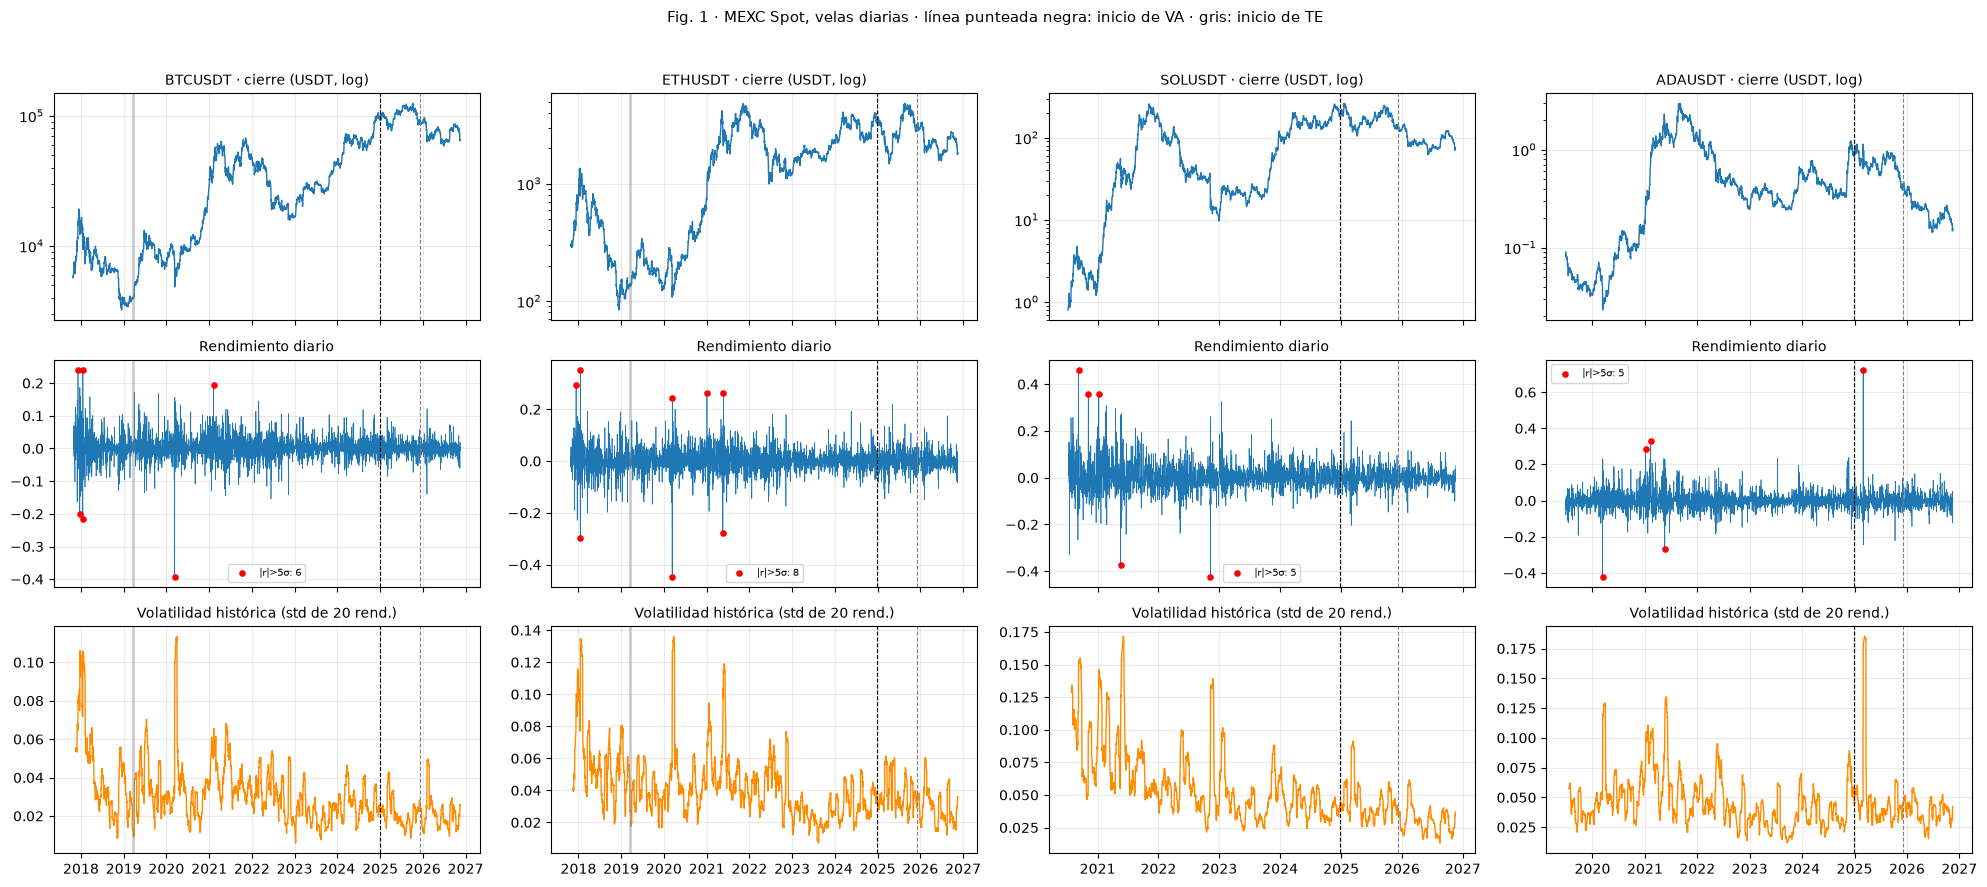

Valores extremos detectados (no se eliminan):


,simbolo,fecha,rendimiento,sigmas
0,BTCUSDT,2017-12-06,0.2405,6.4
1,BTCUSDT,2017-12-21,-0.1993,-5.3
2,BTCUSDT,2018-01-16,-0.2150,-5.7
3,BTCUSDT,2018-01-17,0.2393,6.3
4,BTCUSDT,2020-03-12,-0.3919,-10.4
5,BTCUSDT,2021-02-08,0.1953,5.2
6,ETHUSDT,2017-12-11,0.2928,6.1
7,ETHUSDT,2018-01-16,-0.2988,-6.2
8,ETHUSDT,2018-01-17,0.3523,7.3
9,ETHUSDT,2020-03-12,-0.4460,-9.3


In [12]:
n = len(SIMBOLOS)
fig, axs = plt.subplots(3, n, figsize=(5 * n, 9), sharex="col")
EXTREMOS = []
for j, s in enumerate(SIMBOLOS):
    c = DATOS[s]["close"]
    r = c.pct_change()
    vol = r.rolling(20).std()
    sd_tr = r[r.index < CORTE_VA].std()
    ext = r[r.abs() > 5 * sd_tr]
    for fecha, v in ext.items():
        EXTREMOS.append(dict(simbolo=s, fecha=fecha.date(), rendimiento=round(float(v), 4), sigmas=round(float(v / sd_tr), 1)))
    axs[0, j].plot(c.index, c.values, lw=1)
    axs[0, j].set_yscale("log"); axs[0, j].set_title(f"{s} · cierre (USDT, log)", fontsize=10)
    axs[1, j].plot(r.index, r.values, lw=.5)
    axs[1, j].scatter(ext.index, ext.values, color="red", s=14, zorder=3, label=f"|r|>5σ: {len(ext)}")
    axs[1, j].set_title("Rendimiento diario", fontsize=10); axs[1, j].legend(fontsize=7)
    axs[2, j].plot(vol.index, vol.values, lw=1, color="darkorange")
    axs[2, j].set_title("Volatilidad histórica (std de 20 rend.)", fontsize=10)
    for ax in axs[:, j]:
        ax.axvline(CORTE_VA, color="k", ls="--", lw=.8); ax.axvline(CORTE_TE, color="gray", ls="--", lw=.8)
        ax.grid(alpha=.25)
        for _, hh in huecos_calendario(DATOS[s]).iterrows():
            ax.axvline(hh["hasta"], color="gray", lw=2, alpha=.4)
fig.suptitle("Fig. 1 · MEXC Spot, velas diarias · línea punteada negra: inicio de VA · gris: inicio de TE", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, .96))
fig.savefig(FIG / "fig01_precio_retornos_volatilidad.png", dpi=150, bbox_inches="tight")
plt.show()
EXTREMOS = pd.DataFrame(EXTREMOS)
print("Valores extremos detectados (no se eliminan):")
display(EXTREMOS if len(EXTREMOS) else "ninguno")

**Interpretación (completa con tus resultados):**
- *Faltantes:* …
- *Valores extremos:* … (¿coinciden con eventos de mercado? asociación ≠ causalidad)
- *Cambios de comportamiento:* … (¿cambia la volatilidad entre el periodo de TR y el de VA/TE? Un cambio de régimen reduce la fiabilidad de las referencias fuera de muestra.)

## 10. Estudio técnico: hipótesis verificable
**H1.** La distancia relativa entre el cierre y su SMA de 20 días (`cierre / SMA20 − 1`, calculada con historia hasta *t*) contiene información sobre `y_t` que no está en los 20 rezagos; si es así, **agregarla a la regresión con rezagos reducirá el RMSE en VA** frente a la regresión solo con rezagos.

Aquí solo se hace una **exploración en TR** (correlación de rangos). La verificación formal con VA se hace en el Avance 5. Un patrón visual o una correlación pequeña en TR **no** implica capacidad predictiva.

In [13]:
HIP = []
for s in SIMBOLOS:
    c = DATOS[s]["close"]
    dist = c / c.rolling(20, min_periods=20).mean() - 1          # solo historia hasta t (incluye t)
    tr = SPLIT[s]["TR"]["meta"]
    x = dist.reindex(tr["emision"]).to_numpy()
    y = tr["y"].to_numpy()
    ok = np.isfinite(x)
    rho, p = spearmanr(x[ok], y[ok])
    HIP.append(dict(simbolo=s, n=int(ok.sum()), spearman_rho_TR=round(float(rho), 4), p_valor=round(float(p), 4)))
display(pd.DataFrame(HIP).set_index("simbolo"))
print("Lectura prudente: |rho| pequeño y/o p-valor alto → sin evidencia en TR; aun con p bajo, se confirma (o no) en VA con MAE/RMSE.")

,n,spearman_rho_TR,p_valor
simbolo,,,
BTCUSDT,1612,0.0077,0.7579
ETHUSDT,1612,-0.0065,0.7946
SOLUSDT,1612,0.0344,0.1675
ADAUSDT,1612,0.0163,0.5134


Lectura prudente: |rho| pequeño y/o p-valor alto → sin evidencia en TR; aun con p bajo, se confirma (o no) en VA con MAE/RMSE.


## 11. Cuatro fallos provocados (en copias pequeñas)
Se provocan: **conjunto vacío, fecha duplicada, valor no válido y dimensiones incorrectas** sobre una copia de 40 filas. Se muestra el mensaje y la detención o recuperación esperada. Los datos originales **no se modifican** (se comprueba con un hash antes y después).

In [14]:
SIM_PRUEBA = SIMBOLOS[0]
hash_antes = int(pd.util.hash_pandas_object(DATOS[SIM_PRUEBA]).sum())
base = DATOS[SIM_PRUEBA].head(40).copy()

def corregir_duplicados(df):
    n0 = len(df)
    out = df[~df.index.duplicated(keep="last")].sort_index()
    return out, n0 - len(out)

def prueba(nombre, provocar, accion, recuperar=None):
    try:
        provocar()
    except (DatosVaciosError, FechaDuplicadaError, ValorInvalidoError, DimensionError) as exc:
        print(f"[{nombre}] {type(exc).__name__}: {exc}")
        resultado = recuperar() if recuperar else "flujo detenido antes de entrenar/evaluar; no se inventan datos"
        registrar("prueba controlada", f"{nombre} ({type(exc).__name__})", str(exc), accion, resultado)
        print("   →", resultado, "\n")
    else:
        raise AssertionError(f"[{nombre}] el fallo provocado NO fue detectado: revisa las validaciones.")

# 1) Conjunto vacío
prueba("conjunto vacío", lambda: validar_datos(base.iloc[0:0], "copia_vacia"),
       "detener el flujo e informar fuente/símbolo")

# 2) Fecha duplicada (con recuperación por regla explícita)
dup = pd.concat([base, base.iloc[[5]]]).sort_index()
def recuperar_dup():
    limpio, cambiadas = corregir_duplicados(dup)
    validar_datos(limpio, "copia_corregida")
    return f"se eliminaron {cambiadas} fila(s) (regla: conservar la última); índice único y orden cronológico verificados"
prueba("fecha duplicada", lambda: validar_datos(dup, "copia_duplicada"),
       "eliminar duplicados conservando la última y contar filas cambiadas", recuperar_dup)

# 3) Valor no válido (precio negativo)
mal = base.copy()
mal.iloc[3, mal.columns.get_loc("close")] = -1.0
prueba("valor no válido", lambda: validar_datos(mal, "copia_con_precio_negativo"),
       "detener; identificar columna y fecha; no sustituir por un valor inventado")

# 4) Dimensiones incorrectas
prueba("dimensiones incorrectas", lambda: validar_forma(np.zeros((10, 5)), n_col=LAGS, nombre="X_prueba"),
       "detenerse antes de entrenar e informar forma esperada y recibida")

hash_despues = int(pd.util.hash_pandas_object(DATOS[SIM_PRUEBA]).sum())
control(hash_antes == hash_despues, "¡Los datos originales cambiaron durante las pruebas!", RuntimeError)
print("✔ Datos originales intactos (hash idéntico antes y después).")

[conjunto vacío] DatosVaciosError: copia_vacia: el conjunto está vacío. Revisa la fuente, el símbolo y el periodo.
   → flujo detenido antes de entrenar/evaluar; no se inventan datos 

[fecha duplicada] FechaDuplicadaError: copia_duplicada: 1 fechas duplicadas. Elimínalas con una regla explícita (conservar la última) y registra cuántas filas cambian.
   → se eliminaron 1 fila(s) (regla: conservar la última); índice único y orden cronológico verificados 

[valor no válido] ValorInvalidoError: copia_con_precio_negativo: hay precios no finitos o no positivos. Identifica columna y fecha, y decide sin usar información futura.
   → flujo detenido antes de entrenar/evaluar; no se inventan datos 

[dimensiones incorrectas] DimensionError: X_prueba: forma esperada (n, 20), recibida (10, 5). Revisa LAGS o la construcción de ventanas antes de entrenar.
   → flujo detenido antes de entrenar/evaluar; no se inventan datos 

✔ Datos originales intactos (hash idéntico antes y después).


## 12. Controles antes de evaluar TE
Se verifica: datos y predicciones finitos, fechas y objetivos alineados, escalador ajustado con TR, formas correctas y que **TE no intervino** en ninguna métrica ni decisión.

In [15]:
for s in SIMBOLOS:
    verificar_particiones(s)
    for p in ("TR", "VA", "TE"):
        sp = SPLIT[s][p]
        validar_forma(sp["X"], nombre=f"{s}-{p}")
        control(np.isfinite(sp["X"]).all() and np.isfinite(sp["y"]).all() and np.isfinite(sp["Xs"]).all(),
                f"{s}-{p}: hay valores no finitos.", ValorInvalidoError)
    control(np.allclose(ESC[s].mean_, SPLIT[s]["TR"]["X"].mean(axis=0)), f"{s}: el escalador no se ajustó solo con TR.", FugaInformacionError)
    control(len(SPLIT[s]["lr"].coef_) == LAGS, f"{s}: la regresión no tiene {LAGS} coeficientes.", DimensionError)
control(set(EXPERIMENTOS["conjunto"]) <= {"TR", "VA"}, "TE aparece en experimentos.csv antes de congelar el sistema.", FugaInformacionError)
print("✔ Todos los controles pasaron. TE sigue reservado (0 métricas calculadas sobre TE).")

✔ Todos los controles pasaron. TE sigue reservado (0 métricas calculadas sobre TE).


## 13. Guardado de entregables

In [16]:
for s in SIMBOLOS:
    partes = []
    for p in ("TR", "VA", "TE"):
        sp = SPLIT[s][p]
        d = sp["meta"].copy()
        d.insert(0, "conjunto", p)
        d[NOMBRES_X] = sp["X"]
        partes.append(d)
    pd.concat(partes).to_csv(PROC / f"{s}_ventanas_{LAGS}.csv", index=False)

BIT = pd.DataFrame(BITACORA)
BIT.to_csv(OUT / "bitacora.csv", index=False)
print("Archivos en", ROOT)
for carpeta in (RAW, PROC, OUT, FIG):
    print(f"  {carpeta.relative_to(ROOT)}: {sorted(p.name for p in carpeta.iterdir())}")
print("\nBitácora:")
display(BIT)

Archivos en C:\Users\Diego Horner\Documents\traidingbot\bottrading
  data\raw: ['ADAUSDT_1d_raw.csv', 'BTCUSDT_1d_raw.csv', 'ETHUSDT_1d_raw.csv', 'SOLUSDT_1d_raw.csv', 'metadatos.json']
  data\processed: ['.gitkeep', 'ADAUSDT_1d_limpio.csv', 'ADAUSDT_ventanas_20.csv', 'BTCUSDT_1d_limpio.csv', 'BTCUSDT_ventanas_20.csv', 'ETHUSDT_1d_limpio.csv', 'ETHUSDT_ventanas_20.csv', 'SOLUSDT_1d_limpio.csv', 'SOLUSDT_ventanas_20.csv']
  outputs: ['auditoria_datos.csv', 'bitacora.csv', 'diccionario_datos.csv', 'experimentos.csv', 'ficha_activos.csv', 'tabla_particiones.csv', 'versiones.json']
  figures: ['fig01_precio_retornos_volatilidad.png']

Bitácora:


,fecha,etapa,error,causa,accion_correctiva,verificacion
0,2026-11-18T05:03:28+00:00,limpieza,vela_abierta_excluida en BTCUSDT,1 fila(s) afectadas,excluir la vela del día aún abierta,"validar_datos() sin errores: índice único, ord..."
1,2026-11-18T05:03:28+00:00,limpieza,vela_abierta_excluida en ETHUSDT,1 fila(s) afectadas,excluir la vela del día aún abierta,"validar_datos() sin errores: índice único, ord..."
2,2026-11-18T05:03:28+00:00,limpieza,vela_abierta_excluida en SOLUSDT,1 fila(s) afectadas,excluir la vela del día aún abierta,"validar_datos() sin errores: índice único, ord..."
3,2026-11-18T05:03:28+00:00,limpieza,vela_abierta_excluida en ADAUSDT,1 fila(s) afectadas,excluir la vela del día aún abierta,"validar_datos() sin errores: índice único, ord..."
4,2026-11-18T05:03:28+00:00,auditoría,huecos de calendario en BTCUSDT,1 día(s) faltantes,no se rellenan; las ventanas que los cruzan se...,conteo de ventanas descartadas reportado en la...
5,2026-11-18T05:03:28+00:00,auditoría,huecos de calendario en ETHUSDT,1 día(s) faltantes,no se rellenan; las ventanas que los cruzan se...,conteo de ventanas descartadas reportado en la...
6,2026-11-18T05:03:31+00:00,prueba controlada,conjunto vacío (DatosVaciosError),copia_vacia: el conjunto está vacío. Revisa la...,detener el flujo e informar fuente/símbolo,flujo detenido antes de entrenar/evaluar; no s...
7,2026-11-18T05:03:31+00:00,prueba controlada,fecha duplicada (FechaDuplicadaError),copia_duplicada: 1 fechas duplicadas. Elimínal...,eliminar duplicados conservando la última y co...,se eliminaron 1 fila(s) (regla: conservar la ú...
8,2026-11-18T05:03:31+00:00,prueba controlada,valor no válido (ValorInvalidoError),copia_con_precio_negativo: hay precios no fini...,detener; identificar columna y fecha; no susti...,flujo detenido antes de entrenar/evaluar; no s...
9,2026-11-18T05:03:31+00:00,prueba controlada,dimensiones incorrectas (DimensionError),"X_prueba: forma esperada (n, 20), recibida (10...",detenerse antes de entrenar e informar forma e...,flujo detenido antes de entrenar/evaluar; no s...


## 14. Entregable del Avance 1 y reflexión
**Entregado:** datos originales y procesados, ficha y diccionario, auditoría, tabla de particiones, dos modelos de referencia (MAE/RMSE en TR y VA), hipótesis técnica, cuatro fallos provocados y bitácora.

**Reflexión (completa):**
1. ¿Mejora la regresión lineal al pronóstico cero en VA? ¿En todos los activos? ¿Qué implica para el modelo profundo?
2. ¿Cambia el régimen de volatilidad entre TR y VA? ¿Cómo afecta a la comparación?
3. ¿Qué verificaste para asegurar que ninguna entrada usa información futura?
4. ¿Qué cambiarías antes del Avance 2?